# Field Pixel Time-Series by Residue Class

This notebook extracts pixel values from field-level Sentinel-1 rasters and creates 3 line charts:

1. Backscatter VV
2. Backscatter VH
3. Coherence

Each chart has two lines:
- **Residues Left**
- **Residues Removed**

X-axis: timestamp  
Y-axis: mean pixel value across all pixels in fields for each class.

## 1. Import Libraries and Configure Paths

In [15]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from rasterio.warp import transform_geom
from shapely import wkb
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

sns.set_theme(style="whitegrid")

# -----------------------------
# User configuration
# -----------------------------
DATA_ROOT = Path(r"u:\Kursbiblioteket\GE9010\student_files\Berezkova Kristine (krbe2133)\crop_residue_Dalarna\data\fields\data")

# Field polygons with field_id.
FIELDS_FILE = Path(r"u:\Kursbiblioteket\GE9010\student_files\Berezkova Kristine (krbe2133)\Sebastian_output\field_geometries_samples_crop_residues_crop3_fieldlevel_dalarna.parquet")
FIELD_CRS = "EPSG:3006"

# Labels parquet provided by user.
LABELS_FILE = Path(r"u:\Kursbiblioteket\GE9010\student_files\Berezkova Kristine (krbe2133)\results_pixelencodernet_s1backcoh_samples_crop_residues_crop3_fieldlevel_dalarna.parquet")

FIELD_ID_COL = "field_id"
CLASS_COL = "label"

# Update these if your label encoding is opposite.
LEFT_LABEL = 1
REMOVED_LABEL = 0

BACKSCATTER_DIRNAME = "backscatter"
COHERENCE_DIRNAME = "coherence"

RAW_OUTPUT_CSV = Path("data/pixel_means_raw.csv")
OUTPUT_CSV = Path("data/linechart_means_by_class.csv")

CLASS_NAME_MAP = {
    LEFT_LABEL: "Residues Left",
    REMOVED_LABEL: "Residues Removed",
}


def parse_backscatter_date(filename: str) -> pd.Timestamp:
    dates = re.findall(r"(20\d{6})", filename)
    if not dates:
        return pd.NaT
    return pd.to_datetime(dates[0], format="%Y%m%d", errors="coerce")


def parse_coherence_dates(filename: str):
    dates = re.findall(r"(20\d{6})", filename)
    if len(dates) < 2:
        return pd.NaT, pd.NaT, None

    start = pd.to_datetime(dates[0], format="%Y%m%d", errors="coerce")
    end = pd.to_datetime(dates[1], format="%Y%m%d", errors="coerce")
    if pd.isna(start) or pd.isna(end):
        return pd.NaT, pd.NaT, None

    pair_label = f"{start.strftime('%Y-%m-%d')} to {end.strftime('%Y-%m-%d')}"
    return start, end, pair_label


def infer_backscatter_band_labels(src: rasterio.io.DatasetReader) -> list[str]:
    labels = []
    if src.descriptions and any(src.descriptions):
        for i, desc in enumerate(src.descriptions, start=1):
            d = (desc or "").upper()
            if "VV" in d:
                labels.append("VV")
            elif "VH" in d:
                labels.append("VH")
            else:
                labels.append(f"Band {i}")
    elif src.count == 2:
        labels = ["VV", "VH"]
    else:
        labels = [f"Band {i}" for i in range(1, src.count + 1)]
    return labels


def safe_nanmean(arr: np.ndarray) -> float:
    if arr.size == 0:
        return np.nan
    valid = arr[np.isfinite(arr)]
    if valid.size == 0:
        return np.nan
    return float(valid.mean())


def decode_wkb_geometry_column(df: pd.DataFrame, geometry_col: str = "geometry") -> gpd.GeoDataFrame:
    if geometry_col not in df.columns:
        raise ValueError(f"Missing geometry column '{geometry_col}'.")

    def _decode(val):
        if isinstance(val, (bytes, bytearray, memoryview)):
            return wkb.loads(bytes(val))
        return val

    geometry = df[geometry_col].apply(_decode)
    out = gpd.GeoDataFrame(df.drop(columns=[geometry_col]), geometry=geometry)
    return out

## 2. Load Field Labels and Time-Indexed Raster Stack

In [6]:
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Data root not found: {DATA_ROOT}")

if not FIELDS_FILE.exists():
    raise FileNotFoundError(f"Fields file not found: {FIELDS_FILE}")
if not LABELS_FILE.exists():
    raise FileNotFoundError(f"Labels file not found: {LABELS_FILE}")

# Load field polygons.
fields_df = pd.read_parquet(FIELDS_FILE)
fields_gdf = decode_wkb_geometry_column(fields_df, geometry_col="geometry")
if fields_gdf.crs is None:
    fields_gdf = fields_gdf.set_crs(FIELD_CRS)
if FIELD_ID_COL not in fields_gdf.columns:
    raise ValueError(f"Column '{FIELD_ID_COL}' missing in fields file. Available: {list(fields_gdf.columns)}")
fields_gdf[FIELD_ID_COL] = fields_gdf[FIELD_ID_COL].astype(str)

# Load labels.
labels_df = pd.read_parquet(LABELS_FILE)
if CLASS_COL not in labels_df.columns:
    raise ValueError(f"Column '{CLASS_COL}' missing in labels file. Available: {list(labels_df.columns)}")

# Two supported cases:
# 1) labels file has field_id directly
# 2) labels file has geometry and needs spatial join to field polygons
if FIELD_ID_COL in labels_df.columns:
    labels_df[FIELD_ID_COL] = labels_df[FIELD_ID_COL].astype(str)
    labels_df = labels_df[[FIELD_ID_COL, CLASS_COL]].copy()
else:
    if "geometry" not in labels_df.columns:
        raise ValueError(
            f"Labels file must contain either '{FIELD_ID_COL}' or 'geometry'. Available: {list(labels_df.columns)}"
        )
    labels_gdf = decode_wkb_geometry_column(labels_df, geometry_col="geometry")
    if labels_gdf.crs is None:
        labels_gdf = labels_gdf.set_crs(FIELD_CRS)

    labels_with_id = gpd.sjoin(
        labels_gdf,
        fields_gdf[[FIELD_ID_COL, "geometry"]],
        how="inner",
        predicate="within",
    )
    labels_df = labels_with_id[[FIELD_ID_COL, CLASS_COL]].copy()

labels_df = labels_df[labels_df[CLASS_COL].isin({LEFT_LABEL, REMOVED_LABEL})].copy()
if labels_df.empty:
    raise ValueError(
        f"No label rows after filtering to LEFT_LABEL={LEFT_LABEL} and REMOVED_LABEL={REMOVED_LABEL}."
    )

fields_labeled = fields_gdf.merge(labels_df, on=FIELD_ID_COL, how="inner")
if fields_labeled.empty:
    raise ValueError("No matching field IDs between field geometries and labels.")

print(f"Labeled fields: {len(fields_labeled)}")
print(fields_labeled[CLASS_COL].value_counts(dropna=False))

Labeled fields: 48
label
1    29
0    19
Name: count, dtype: int64


## 3. Validate CRS, Alignment, and Field Masks

In [7]:
def field_geometry_in_raster_crs(field_geom, field_crs, raster_crs):
    if field_crs == raster_crs:
        return field_geom
    return transform_geom(str(field_crs), str(raster_crs), field_geom)


def extract_values_inside_geometry(src, band_index, field_geom_proj):
    band = src.read(band_index).astype("float64")
    nodata = src.nodata
    if nodata is not None:
        band[band == nodata] = np.nan

    mask = geometry_mask(
        [field_geom_proj],
        out_shape=(src.height, src.width),
        transform=src.transform,
        invert=True,
    )
    values = band[mask]
    values = values[np.isfinite(values)]
    return values


print("CRS helpers ready.")

CRS helpers ready.


## 4. Extract Pixel Values per Field and Timestamp

This step creates a long-format table with one row per extracted pixel value.

In [16]:
records = []
missing_field_dirs = []

for row in fields_labeled.itertuples(index=False):
    field_id = str(getattr(row, FIELD_ID_COL))
    class_label = getattr(row, CLASS_COL)
    field_geom = row.geometry.__geo_interface__

    field_dir = DATA_ROOT / field_id
    backscatter_dir = field_dir / BACKSCATTER_DIRNAME
    coherence_dir = field_dir / COHERENCE_DIRNAME

    if not field_dir.exists():
        missing_field_dirs.append(field_id)
        continue

    # Backscatter (usually VV, VH in same raster)
    if backscatter_dir.exists():
        for tif_path in sorted(backscatter_dir.glob("*.tif")):
            ts = parse_backscatter_date(tif_path.name)
            with rasterio.open(tif_path) as src:
                geom_proj = field_geometry_in_raster_crs(field_geom, fields_labeled.crs, src.crs)
                band_labels = infer_backscatter_band_labels(src)

                for b in range(1, src.count + 1):
                    variable = band_labels[b - 1] if b - 1 < len(band_labels) else f"Band {b}"
                    values = extract_values_inside_geometry(src, b, geom_proj)
                    for val in values:
                        records.append(
                            {
                                "field_id": field_id,
                                "class_label": class_label,
                                "variable": variable,
                                "timestamp": ts,
                                "pair_label": None,
                                "pixel_value": float(val),
                                "source_file": tif_path.name,
                            }
                        )

    # Coherence (single-band expected)
    if coherence_dir.exists():
        for tif_path in sorted(coherence_dir.glob("*.tif")):
            start_ts, end_ts, pair_label = parse_coherence_dates(tif_path.name)
            with rasterio.open(tif_path) as src:
                geom_proj = field_geometry_in_raster_crs(field_geom, fields_labeled.crs, src.crs)
                values = extract_values_inside_geometry(src, 1, geom_proj)
                for val in values:
                    records.append(
                        {
                            "field_id": field_id,
                            "class_label": class_label,
                            "variable": "Coherence",
                            "timestamp": start_ts,
                            "pair_label": pair_label,
                            "pixel_value": float(val),
                            "source_file": tif_path.name,
                        }
                    )

if missing_field_dirs:
    print(f"Warning: {len(missing_field_dirs)} field folders were not found under {DATA_ROOT}.")

pixels_long = pd.DataFrame(records)
if pixels_long.empty:
    raise RuntimeError("No pixel records extracted. Check paths, field IDs, and raster availability.")

pixels_long["class_label"] = pixels_long["class_label"].map(CLASS_NAME_MAP).fillna(pixels_long["class_label"])
pixels_long = pixels_long.dropna(subset=["timestamp", "pixel_value"]).copy()

print(f"Extracted pixel rows: {len(pixels_long):,}")
pixels_long.head()

Extracted pixel rows: 592,288


,field_id,class_label,variable,timestamp,pair_label,pixel_value,source_file
0,22629,Residues Left,VV,2024-06-02,None,-18.171219,backscatter_Gamma0_dB_S1A_IW_SLC__1SDV_2024060...
1,22629,Residues Left,VV,2024-06-02,None,-20.392111,backscatter_Gamma0_dB_S1A_IW_SLC__1SDV_2024060...
2,22629,Residues Left,VV,2024-06-02,None,-17.560480,backscatter_Gamma0_dB_S1A_IW_SLC__1SDV_2024060...
3,22629,Residues Left,VV,2024-06-02,None,-15.408431,backscatter_Gamma0_dB_S1A_IW_SLC__1SDV_2024060...
4,22629,Residues Left,VV,2024-06-02,None,-18.995033,backscatter_Gamma0_dB_S1A_IW_SLC__1SDV_2024060...


## 5. Assign Residue Classes and Build Long-Format Table

In [9]:
pixels_long = pixels_long[pixels_long["class_label"].isin(CLASS_NAME_MAP.values())].copy()
print("Class labels in long table:", sorted(pixels_long["class_label"].dropna().unique()))
print("Variables in long table:", sorted(pixels_long["variable"].dropna().unique()))

Class labels in long table: ['Residues Left', 'Residues Removed']
Variables in long table: ['Coherence', 'VH', 'VV']


## 6. Compute Mean Pixel Values by Timestamp and Class

In [17]:
# Save raw pixel-level table (can be large).
RAW_OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)

pixels_long.to_csv(RAW_OUTPUT_CSV, index=False)

agg = (
    pixels_long
    .groupby(["class_label", "variable", "timestamp", "pair_label"], as_index=False, dropna=False)
    .agg(mean_pixel_value=("pixel_value", "mean"))
    .sort_values(["variable", "timestamp", "class_label"])
)

agg.to_csv(OUTPUT_CSV, index=False)

vv_agg = agg[agg["variable"].str.upper() == "VV"].copy()
vh_agg = agg[agg["variable"].str.upper() == "VH"].copy()
coh_agg = agg[agg["variable"].str.lower() == "coherence"].copy()

print(f"Saved raw table: {RAW_OUTPUT_CSV}")
print(f"Saved aggregated table: {OUTPUT_CSV}")
print(f"Aggregated rows: {len(agg):,}")

Saved raw table: data\pixel_means_raw.csv
Saved aggregated table: data\linechart_means_by_class.csv
Aggregated rows: 64


## 7. Plot Line Chart: Backscatter VV

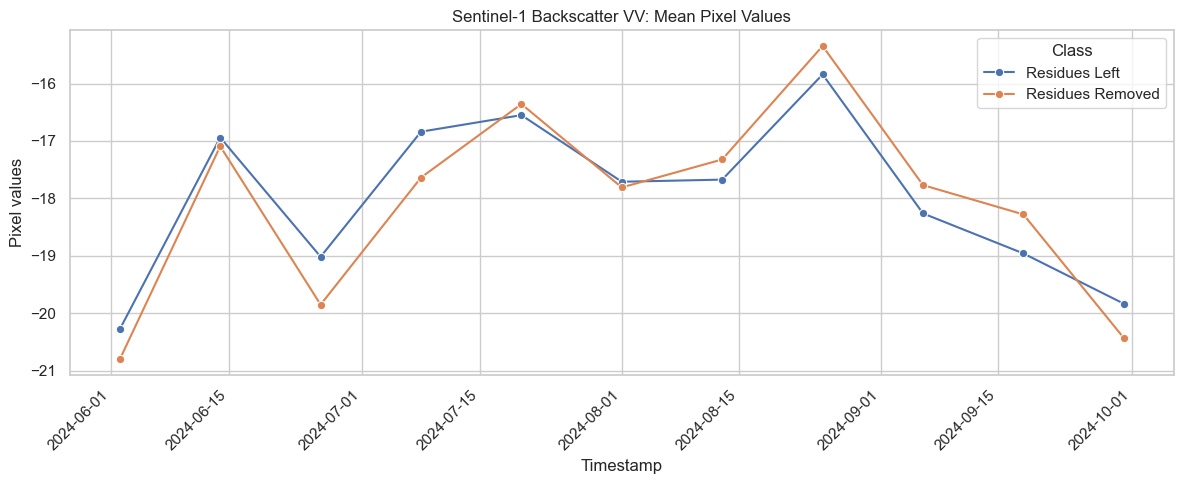

In [18]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=vv_agg,
    x="timestamp",
    y="mean_pixel_value",
    hue="class_label",
    hue_order=["Residues Left", "Residues Removed"],
    marker="o",
)
plt.title("Sentinel-1 Backscatter VV: Mean Pixel Values")
plt.xlabel("Timestamp")
plt.ylabel("Pixel values")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.xticks(rotation=45, ha="right")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

## 8. Plot Line Chart: Backscatter VH

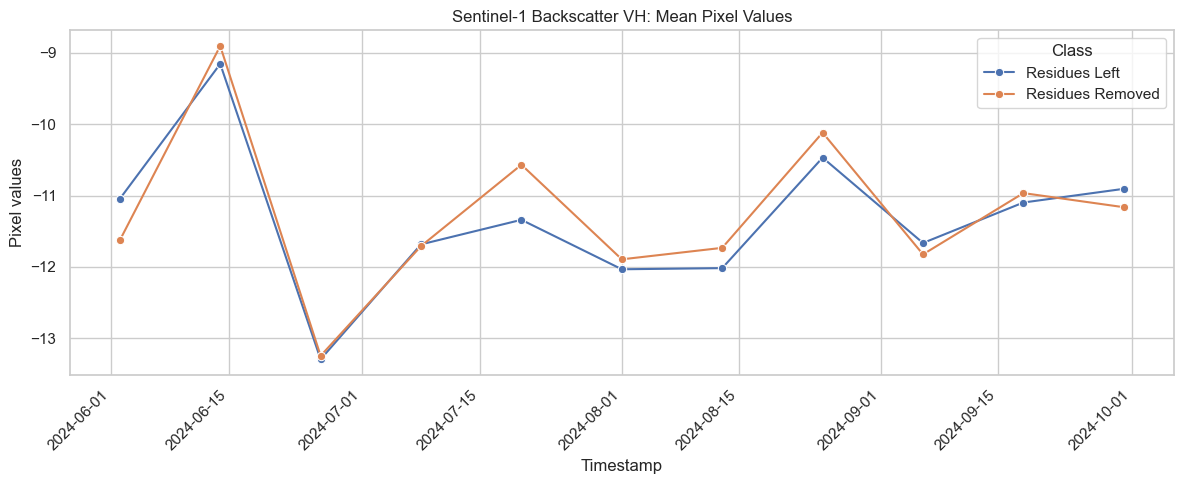

In [19]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=vh_agg,
    x="timestamp",
    y="mean_pixel_value",
    hue="class_label",
    hue_order=["Residues Left", "Residues Removed"],
    marker="o",
)
plt.title("Sentinel-1 Backscatter VH: Mean Pixel Values")
plt.xlabel("Timestamp")
plt.ylabel("Pixel values")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.xticks(rotation=45, ha="right")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

## 9. Plot Line Chart: Coherence

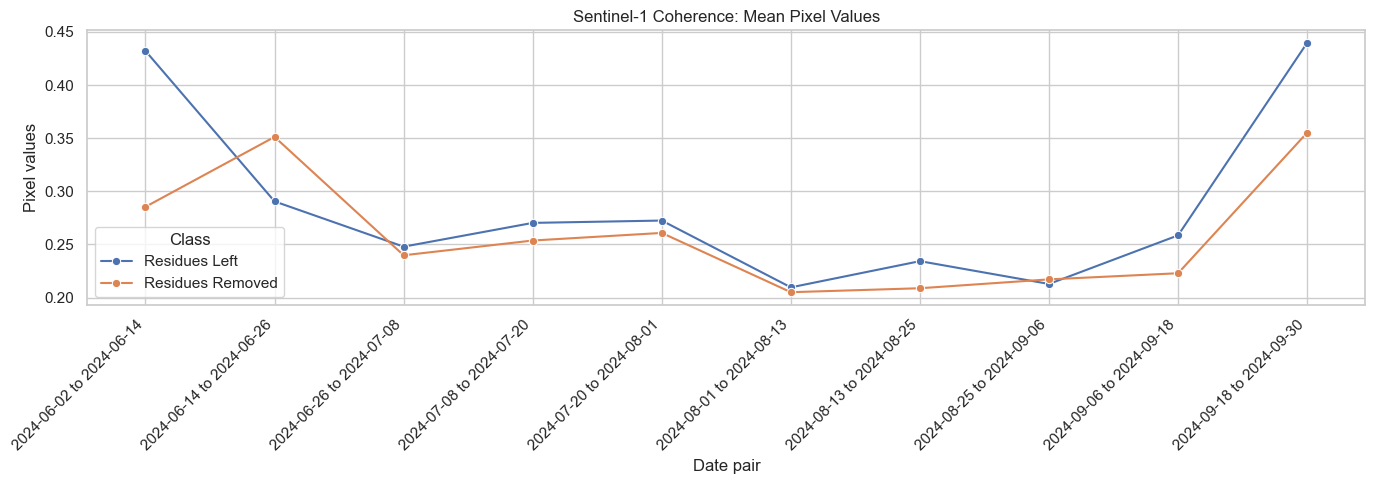

In [20]:
coh_plot = coh_agg.copy()
coh_plot = coh_plot.dropna(subset=["pair_label"]).sort_values("timestamp")

pair_order = coh_plot["pair_label"].drop_duplicates().tolist()

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=coh_plot,
    x="pair_label",
    y="mean_pixel_value",
    hue="class_label",
    hue_order=["Residues Left", "Residues Removed"],
    marker="o",
)
plt.title("Sentinel-1 Coherence: Mean Pixel Values")
plt.xlabel("Date pair")
plt.ylabel("Pixel values")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [14]:
print("Diagnostics")
print("-" * 40)
print("Rows by variable/class:")
print(
    pixels_long.groupby(["variable", "class_label"]).size().rename("n_rows").reset_index()
)
print("\nTimestamp range by variable:")
print(
    pixels_long.groupby("variable")["timestamp"].agg(["min", "max", "nunique"]).reset_index()
)
print(f"\nRaw output CSV: {RAW_OUTPUT_CSV}")
print(f"Aggregated output CSV: {OUTPUT_CSV}")

Diagnostics
----------------------------------------
Rows by variable/class:
    variable       class_label  n_rows
0  Coherence     Residues Left   94800
1  Coherence  Residues Removed   90290
2         VH     Residues Left  104280
3         VH  Residues Removed   99319
4         VV     Residues Left  104280
5         VV  Residues Removed   99319

Timestamp range by variable:
    variable        min        max  nunique
0  Coherence 2024-06-02 2024-09-18       10
1         VH 2024-06-02 2024-09-30       11
2         VV 2024-06-02 2024-09-30       11

Raw output CSV: data\pixel_means_raw.csv
Aggregated output CSV: data\linechart_means_by_class.csv
